# GISPR Recap — Modules 3, 4 and 5 in three maps

A recap of one point from each of the past three weeks.

ArcPy cells run only in Pro; each one is paired with an open-source cell that draws the same idea inline.

| Module | Key idea | Map |
|---|---|---|
| 3 — Vector data | **A spatial join compares coordinate numbers, so both layers must share a CRS** | Partner points before and after `.to_crs()` |
| 4 — Vector operations | **Operations chain: buffer → overlay → summarize** | Parcel land inside a 150 ft stream buffer |
| 5 — Intro to raster | **A raster is an array + transform + CRS; inspect before you overlay** | WRIA 8 DEM with watersheds reprojected onto it |

The common thread: **every one of these depends on the CRS.** The vectors are in WA State Plane North (EPSG:2926, US feet); the rasters are in UTM 10N (EPSG:32610, metres).

In [1]:
# [Python] Setup — point these two paths at your Module 3 and Module 5 folders
from pathlib import Path
import zipfile, warnings
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt

M3_DIR = Path(r"C:\Users\mwebe\OneDrive\UW Program\GISPR\Module 3")   # change to your path - holds data/ or GISPR_Module3_Data.zip
M5_DIR = Path(r"C:\Users\mwebe\OneDrive\UW Program\GISPR\Module 5")   # change to your path - holds the .tif files or module5_rasters.zip

def find_folder(base, must_have, zip_name, unzip_to, usual=()):
    """Folder holding `must_have`: the usual spots first, then the shallowest match below `base`,
    skipping _backup / _tmp / hidden folders. Unzips `zip_name` first if nothing is found."""
    def search():
        for sub in usual:                                       # e.g. data/, GISPR_Module3_Data/data
            if (base / sub / must_have).exists():
                return base / sub
        hits = [p.parent for p in base.rglob(must_have)
                if not any(part.startswith(("_", ".")) for part in p.relative_to(base).parts)]
        return min(hits, key=lambda p: len(p.parts)) if hits else None
    found = search()
    if found is None and (base / zip_name).exists():
        zipfile.ZipFile(base / zip_name).extractall(base / unzip_to)
        found = search()
    if found is None:
        raise FileNotFoundError(f"No {must_have} or {zip_name} under {base} — check the path")
    return found

DATA = find_folder(M3_DIR, "salmon_watersheds.gdb", "GISPR_Module3_Data.zip", ".",
                   usual=(".", "data", "GISPR_Module3_Data/data"))
RAS  = find_folder(M5_DIR, "wria8_dem_30m.tif", "module5_rasters.zip", "module5_rasters",
                   usual=(".", "module5_rasters", "data"))

# Guard: the v1 (Oct 4) synthetic bundle has no OWNER_TYPE — make sure we found the current one
if "OWNER_TYPE" not in gpd.read_file(DATA / "parcels.gdb", layer="Parcels", rows=1).columns:
    raise ValueError(f"{DATA} looks like the old v1 data bundle (no OWNER_TYPE in Parcels) — "
                     "point M3_DIR at the folder holding the current GISPR_Module3_Data")

COURSE_EPSG  = 2926                     # NAD83(HARN) / Washington North (US ft)
PURPLE, GOLD = "#4b2e83", "#b7a57a"
OUT = Path.cwd()                        # recap.gdb is written next to this notebook

try:
    import arcpy
    HAS_ARCPY = True
    arcpy.env.overwriteOutput = True
    GDB = str(OUT / "recap.gdb")
    if not arcpy.Exists(GDB):
        arcpy.management.CreateFileGDB(str(OUT), "recap.gdb")
    arcpy.env.workspace = GDB
except ModuleNotFoundError:
    HAS_ARCPY = False

print("ArcPy available:", HAS_ARCPY)
print("Module 3 data:  ", DATA)
print("Module 5 rasters:", RAS)

watersheds = gpd.read_file(DATA / "salmon_watersheds.gdb", layer="watersheds")   # EPSG:2926
print("watersheds:", len(watersheds), "polygons, EPSG:", watersheds.crs.to_epsg())

ArcPy available: False
Module 3 data:   C:\Users\mwebe\OneDrive\UW Program\GISPR\Module 3\GISPR_Module3_Data\data
Module 5 rasters: C:\Users\mwebe\OneDrive\UW Program\GISPR\Module 5\GISPR_Module5_Data
watersheds: 15 polygons, EPSG: 2926


---
## Module 3 — An example join

**Why might we get NA results in a join?** 

When the layers are aligned in the example below the expected result is **field CSV: 38 of 38 matched** (after the lab drops the 2 rows with no `obs_id`) and **partner: 23 of 25 matched** — two partner sites (PA-024, PA-025) genuinely sit outside every watershed. 

**Remember:** ArcGIS `Spatial Join` projects on the fly, so mixed-CRS inputs *just work* in Pro. GeoPandas does not — you have to `.to_crs()` yourself.

In [55]:
# [Python / ArcPy] Module 3 — the ESRI way: Spatial Join reprojects on the fly (Pro only)
if HAS_ARCPY:
    partner_fc = arcpy.conversion.JSONToFeatures(str(DATA / "salmon_obs_partner_agency.geojson"),
                                                 "partner_obs", geometry_type="POINT")[0]   # stays in 4326
    ws_fc = str(DATA / "salmon_watersheds.gdb" / "watersheds")                              # 2926
    sj = arcpy.analysis.SpatialJoin(partner_fc, ws_fc, "partner_in_ws",
                                    join_operation="JOIN_ONE_TO_ONE", join_type="KEEP_ALL",
                                    match_option="WITHIN")[0]
    names = [r[0] for r in arcpy.da.SearchCursor(sj, ["WATERSHED_NAME"])]
    print(f"ArcPy Spatial Join: {sum(n is not None and n != '' for n in names)} of {len(names)} partner points matched — "
          "no reprojection needed")
    print("partner_in_ws is in recap.gdb — symbolize on WATERSHED_NAME to show the two unmatched sites.")
else:
    print("ArcPy reference cell — skipped (no arcpy in this environment).")

ArcPy Spatial Join: 23 of 25 partner points matched — no reprojection needed
partner_in_ws is in recap.gdb — symbolize on WATERSHED_NAME to show the two unmatched sites.


In [56]:
# [Python] Module 3 — reproduce NaN results, then fix them
partner_raw = gpd.read_file(DATA / "salmon_obs_partner_agency.geojson")            # EPSG:4326 (degrees)
csv = pd.read_csv(DATA / "salmon_obs.csv")
csv = csv.dropna(subset=[" Obs ID "])                                              # the lab's Step 3 null drop
field_raw = gpd.GeoDataFrame(csv, crs="EPSG:4326",
                             geometry=gpd.points_from_xy(csv["Longitude"], csv["Latitude"]))  # x = LON, y = LAT
ws = watersheds[["WATERSHED_NAME", "geometry"]]

def matched(left):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        j = gpd.sjoin(left, ws, how="left", predicate="within")
    flag = " ⚠ CRS mismatch warning" if any("CRS mismatch" in str(x.message) for x in w) else ""
    return j, f"{j['WATERSHED_NAME'].notna().sum()} of {len(j)} matched{flag}"

print("❌ BEFORE (no .to_crs):")
print("   field CSV:", matched(field_raw)[1]);  print("   partner:  ", matched(partner_raw)[1])

field_2926, partner_2926 = field_raw.to_crs(COURSE_EPSG), partner_raw.to_crs(COURSE_EPSG)   # ← the fix
partner_j, msg = matched(partner_2926)
print("✅ AFTER .to_crs(2926):")
print("   field CSV:", matched(field_2926)[1]); print("   partner:  ", msg)
print("   outside every watershed:", partner_j.loc[partner_j["WATERSHED_NAME"].isna(), "SiteCode"].tolist())

# Three-line diagnostic for any all-NaN join
print("\nDiagnostic — CRS:", partner_raw.crs.to_epsg(), "vs", ws.crs.to_epsg())
print("  partner x-range:", partner_raw.total_bounds[[0, 2]].round(2), " watershed x-range:", ws.total_bounds[[0, 2]].round(0))

❌ BEFORE (no .to_crs):
   field CSV: 0 of 38 matched ⚠ CRS mismatch warning
   partner:   0 of 25 matched ⚠ CRS mismatch warning
✅ AFTER .to_crs(2926):
   field CSV: 38 of 38 matched
   partner:   23 of 25 matched
   outside every watershed: ['PA-024', 'PA-025']

Diagnostic — CRS: 4326 vs 2926
  partner x-range: [-122.43 -121.9 ]  watershed x-range: [1245526. 1492384.]


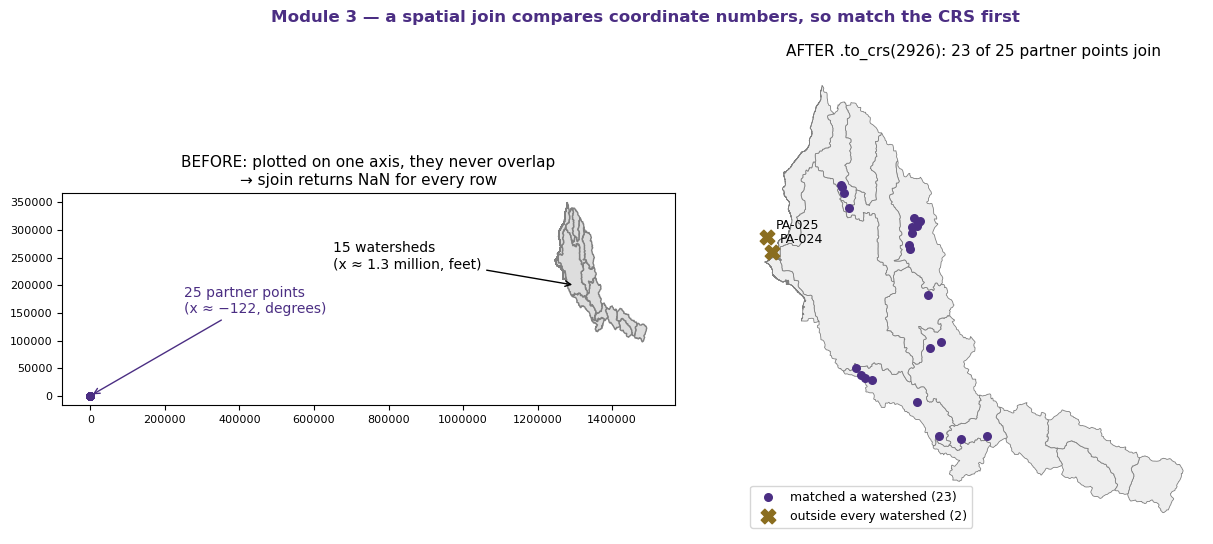

In [57]:
# [Python] Module 3 — the map: same points, same watersheds, before vs after .to_crs()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))

ws.plot(ax=a1, color="#dddddd", edgecolor="grey")
partner_raw.plot(ax=a1, color=PURPLE, markersize=25)
a1.annotate("25 partner points\n(x ≈ −122, degrees)", xy=(-122, 47), xytext=(250_000, 150_000),
            arrowprops=dict(arrowstyle="->", color=PURPLE), color=PURPLE, fontsize=10)
a1.annotate("15 watersheds\n(x ≈ 1.3 million, feet)", xy=(1_300_000, 200_000), xytext=(650_000, 230_000),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
a1.set_title("BEFORE: plotted on one axis, they never overlap\n→ sjoin returns NaN for every row", fontsize=11)
a1.ticklabel_format(style="plain"); a1.tick_params(labelsize=8)

ws.plot(ax=a2, color="#eeeeee", edgecolor="grey", linewidth=0.6)
inside, outside = partner_j[partner_j["WATERSHED_NAME"].notna()], partner_j[partner_j["WATERSHED_NAME"].isna()]
inside.plot(ax=a2, color=PURPLE, marker="o", markersize=30, label=f"matched a watershed ({len(inside)})")
outside.plot(ax=a2, color="#8a6d1f", marker="X", markersize=110, label=f"outside every watershed ({len(outside)})")
for _, r in outside.iterrows():
    a2.annotate(r["SiteCode"], (r.geometry.x, r.geometry.y), xytext=(6, 6), textcoords="offset points", fontsize=9)
a2.set_title("AFTER .to_crs(2926): 23 of 25 partner points join", fontsize=11)
a2.legend(loc="lower left", fontsize=9); a2.set_axis_off()
fig.suptitle("Module 3 — a spatial join compares coordinate numbers, so match the CRS first", fontweight="bold", color=PURPLE)
plt.tight_layout(); plt.show()

---
## Module 4 — Operations chain: buffer → overlay → summarize

Buffer, clip, overlay and spatial join are rarely used alone. Here: buffer the streams 150 ft, intersect the buffer with parcels,
and report how much riparian land each owner type holds. Distances work in feet *because* everything is in EPSG:2926 (Washington North NAD83 feet)

In [58]:
# [Python / ArcPy] Module 4 — Pairwise Buffer → Pairwise Intersect → Statistics (Pro only)
if HAS_ARCPY:
    streams_fc = str(DATA / "salmon_watersheds.gdb" / "streams")
    parcels_fc = str(DATA / "parcels.gdb" / "Parcels")
    buf = arcpy.analysis.PairwiseBuffer(streams_fc, "rip_buf_150ft", "150 Feet", dissolve_option="ALL")[0]
    rip = arcpy.analysis.PairwiseIntersect([parcels_fc, buf], "riparian_parcels")[0]
    arcpy.management.CalculateGeometryAttributes(rip, [["RIP_ACRES", "AREA"]], area_unit="ACRES")
    stats = arcpy.analysis.Statistics(rip, "rip_by_owner", [["RIP_ACRES", "SUM"]], "OWNER_TYPE")[0]
    print(pd.DataFrame(arcpy.da.TableToNumPyArray(stats, ["OWNER_TYPE", "SUM_RIP_ACRES"])).round(2))
    print("rip_buf_150ft and riparian_parcels are in recap.gdb — ready to symbolize in Pro.")
else:
    print("ArcPy reference cell — skipped (no arcpy in this environment).")

  OWNER_TYPE  SUM_RIP_ACRES
0       CITY         135.03
1     COUNTY          99.91
2     SCHOOL           1.47
3      STATE         328.45
rip_buf_150ft and riparian_parcels are in recap.gdb — ready to symbolize in Pro.


            parcels  riparian_acres
OWNER_TYPE                         
STATE            52           328.4
CITY             86           135.0
COUNTY           30            99.9
SCHOOL            3             1.5


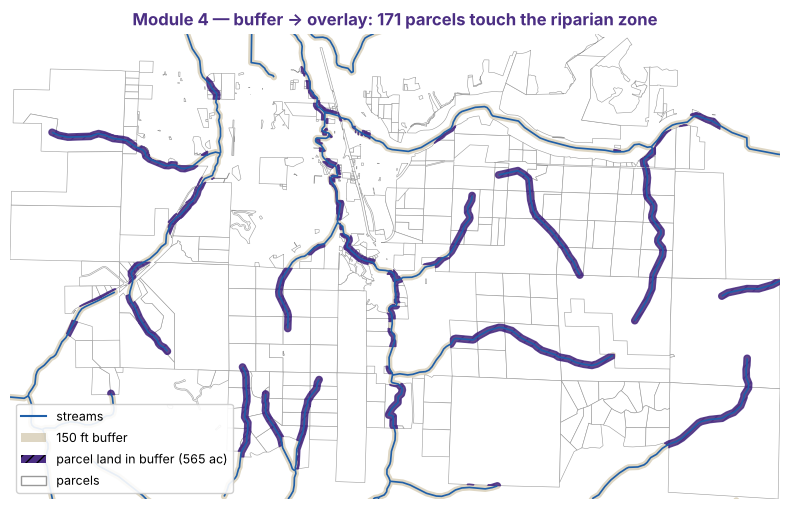

In [6]:
# [Python] Module 4 — the same chain in GeoPandas, then the map
BUFFER_FT, SQFT_PER_ACRE = 150, 43_560
streams = gpd.read_file(DATA / "salmon_watersheds.gdb", layer="streams")
parcels = gpd.read_file(DATA / "parcels.gdb", layer="Parcels")
assert streams.crs == parcels.crs == watersheds.crs          # Module 3 habit: check before operating

rip_buf = gpd.GeoDataFrame(geometry=[streams.buffer(BUFFER_FT).union_all()], crs=streams.crs)   # buffer + dissolve
rip = gpd.overlay(parcels[["PARCEL_ID", "OWNER_TYPE", "geometry"]], rip_buf, how="intersection")
rip["rip_acres"] = rip.area / SQFT_PER_ACRE
summary = (rip.groupby("OWNER_TYPE")
              .agg(parcels=("PARCEL_ID", "nunique"), riparian_acres=("rip_acres", "sum"))
              .round(1).sort_values("riparian_acres", ascending=False))
print(summary)

fig, ax = plt.subplots(figsize=(8, 7))
xmin, ymin, xmax, ymax = parcels.total_bounds
parcels.plot(ax=ax, color="white", edgecolor="#999999", linewidth=0.4)
rip_buf.clip(parcels.total_bounds).plot(ax=ax, color=GOLD, alpha=0.45)
streams.clip(parcels.total_bounds).plot(ax=ax, color="#1f5fa8", linewidth=1.2)
rip.plot(ax=ax, color=PURPLE, edgecolor=PURPLE, hatch="///", alpha=0.85)
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax); ax.set_axis_off()
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color="#1f5fa8", lw=1.5, label="streams"),
                   Patch(facecolor=GOLD, alpha=0.45, label=f"{BUFFER_FT} ft buffer"),
                   Patch(facecolor=PURPLE, hatch="///", label=f"parcel land in buffer ({rip['rip_acres'].sum():.0f} ac)"),
                   Patch(facecolor="white", edgecolor="#999999", label="parcels")],
          loc="lower left", fontsize=9, framealpha=0.9)
ax.set_title(f"Module 4 — buffer → overlay: {rip['PARCEL_ID'].nunique()} parcels touch the riparian zone",
             fontweight="bold", color=PURPLE)
plt.tight_layout(); plt.show()

---
## Module 5 — A raster is an array + transform + CRS: inspect before you overlay

Run the first-inspection checklist (CRS · extent · resolution · dtype · NoData · value range) before using any raster.
Here it catches the same problem as Module 3: the DEM is in **EPSG:32610 (metres)** while the watersheds are in **EPSG:2926 (feet)**.
Reproject the *vector* to the raster's CRS for display — it's cheap and leaves the cell values untouched.

#### What do we mean exactly by 'a raster is an array + transform + CRS?'

1. The array: what are the values? A grid of numbers, 2,569 rows × 2,668 columns of float32 elevations in metres. On its own it knows nothing about location. dem[1200, 1500] is 127.1, but the array can’t tell you where that is. It’s just the cell at row 1200, column 1500.

2. The transform: where does each cell sit? Six numbers that turn a row and column into map coordinates:

   ```
        Affine(30.0,  0.0,  539550.0,     # cell width 30, no rotation, x of the left edge
        0.0, -30.0, 5311890.0)    # no rotation, cell height −30, y of the top edge
   ```

So x = 539,550 + 30 × column and y = 5,311,890 − 30 × row. The height is negative because row 0 is at the top and y gets smaller going down. Applied to cell (1200, 1500), that gives the cell centre at (584,565, 5,275,875). In ArcGIS this is the extent plus the cell size. It’s also exactly what a .tfw world file stores.

3. The CRS: what do those coordinates mean? EPSG:32610 says they are metres in UTM zone 10N. Without it, (584,565, 5,275,875) is just two numbers. With it, the point resolves to about 47.63° N, 121.87° W, near Snoqualmie. This is the Spatial Reference in Pro.

In [59]:
# [Python / ArcPy] Module 5 — Raster properties and add the DEM to the map (Pro only)
if HAS_ARCPY:
    dem_a = arcpy.Raster(str(RAS / "wria8_dem_30m.tif"))
    print("CRS:", dem_a.spatialReference.name, "| cell:", dem_a.meanCellWidth, "| type:", dem_a.pixelType,
          "| NoData:", dem_a.noDataValue, "| range:", round(dem_a.minimum, 1), "–", round(dem_a.maximum, 1))
    try:
        arcpy.mp.ArcGISProject("CURRENT").activeMap.addDataFromPath(str(RAS / "wria8_dem_30m.tif"))
    except Exception:
        pass   # no open map (e.g. a standalone Pro env outside the app)
else:
    print("ArcPy reference cell — skipped (no arcpy in this environment).")

CRS: WGS_1984_UTM_Zone_10N | cell: 30.0 | type: F32 | NoData: -9999.0 | range: -1.5 – 1895.3


In [ ]:
# [Python] Module 5 — inspection checklist, then the map
import rasterio
with rasterio.open(RAS / "wria8_dem_30m.tif") as src:
    dem = src.read(1, masked=True)                    # masked=True → NoData cells excluded from stats and plot
    print("CRS:", src.crs, "| res:", src.res, "| shape:", src.shape, "| dtype:", src.dtypes[0], "| NoData:", src.nodata)
    print(f"Elevation: {dem.min():.0f} – {dem.max():.0f} m (mean {dem.mean():.0f})")
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]
    raster_crs = src.crs

print("Vector CRS:", watersheds.crs.to_epsg(), "≠ raster CRS:", raster_crs.to_epsg(), "→ reproject the watersheds")
ws_utm = watersheds.to_crs(raster_crs)

fig, ax = plt.subplots(figsize=(8, 7.5))
land = plt.matplotlib.colors.ListedColormap(plt.cm.terrain(np.linspace(0.25, 1, 256)))   # terrain minus its "water" blues
im = ax.imshow(dem, extent=extent, cmap=land, vmin=0)
ws_utm.boundary.plot(ax=ax, color="black", linewidth=0.7)
plt.colorbar(im, ax=ax, shrink=0.7, label="Elevation (m)")
ax.set_title("Module 5 — WRIA 8 DEM (EPSG:32610) with watersheds reprojected onto it",
             fontweight="bold", color=PURPLE, fontsize=11)
ax.set_xlabel("UTM 10N easting (m)"); ax.set_ylabel("northing (m)"); ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

NameError: name 'rasterio' is not defined

---
### Forward link → Module 6
Module 6 joins the last two maps: zonal statistics summarize the DEM (and slope and land cover) **by watershed** — raster values aggregated to vector zones, which only works once the CRSs agree.